# Definição de arquitetura neural e treino supervisionado

- **Repositório:** `deep-learning-neural-networks`  
- **Tecnologias:** TensorFlow  
- **Arquivo Original:** `criandoModelo.ipynb`  

---


# Exemplo 3: Criando um modelo (treinando).

In [ ]:
%pip install gensim
import gensim


In [1]:
from gensim.models import Word2Vec

Da documentação do Gensim, alguns parâmetros da função Word2Vec:

- min_count = int - Ignores all words with total absolute frequency lower than this - (2, 100)

- window = int - The maximum distance between the current and predicted word within a sentence. E.g. window words on the left and window words on the left of our target - (2, 10)

- size = int - Dimensionality of the feature vectors. - (50, 300)

- sample = float - The threshold for configuring which higher-frequency words are randomly downsampled. Highly influencial. - (0, 1e-5)

- alpha = float - The initial learning rate - (0.01, 0.05)

- min_alpha = float - Learning rate will linearly drop to min_alpha as training progresses. To set it: alpha - (min_alpha * epochs) ~ 0.00

- negative = int - If > 0, negative sampling will be used, the int for negative specifies how many "noise words" should be drown. If set to 0, no negative sampling is used. - (5, 20)

- workers = int - Use these many worker threads to train the model (=faster training with multicore machines)

In [2]:
# corpus de treinamento
corpus = [['this', 'is', 'the', 'first', 'sentence', 'for', 'word2vec'],
			['this', 'is', 'the', 'second', 'sentence'],
			['yet', 'another', 'sentence'],
			['one', 'more', 'sentence'],
			['and', 'the', 'final', 'sentence']]

corpus2 = [['este', 'eh', 'o', 'primeiro', 'texto', 'para', 'word2vec'],
			['este', 'eh', 'o', 'segundo', 'texto'],
			['e', 'outro', 'texto'],
			['mais', 'um', 'texto'],
			['e', 'o', 'ultimo', 'texto']]

# treinamento
modelo = Word2Vec(corpus, min_count=1)

In [3]:
# modelo
print(modelo)

Word2Vec<vocab=14, vector_size=100, alpha=0.025>


In [6]:
# vocabulario criado
words = list(modelo.wv.index_to_key)
print(words)

['sentence', 'the', 'is', 'this', 'final', 'and', 'more', 'one', 'another', 'yet', 'second', 'word2vec', 'for', 'first']


In [7]:
# vetor para um token
print(modelo.wv['sentence'])

[-5.3622725e-04  2.3643136e-04  5.1033497e-03  9.0092728e-03
 -9.3029495e-03 -7.1168090e-03  6.4588725e-03  8.9729885e-03
 -5.0154282e-03 -3.7633716e-03  7.3805046e-03 -1.5334714e-03
 -4.5366134e-03  6.5540518e-03 -4.8601604e-03 -1.8160177e-03
  2.8765798e-03  9.9187379e-04 -8.2852151e-03 -9.4488179e-03
  7.3117660e-03  5.0702621e-03  6.7576934e-03  7.6286553e-04
  6.3508903e-03 -3.4053659e-03 -9.4640139e-04  5.7685734e-03
 -7.5216377e-03 -3.9361035e-03 -7.5115822e-03 -9.3004224e-04
  9.5381187e-03 -7.3191668e-03 -2.3337686e-03 -1.9377411e-03
  8.0774371e-03 -5.9308959e-03  4.5162440e-05 -4.7537340e-03
 -9.6035507e-03  5.0072931e-03 -8.7595852e-03 -4.3918253e-03
 -3.5099984e-05 -2.9618145e-04 -7.6612402e-03  9.6147433e-03
  4.9820580e-03  9.2331432e-03 -8.1579173e-03  4.4957981e-03
 -4.1370760e-03  8.2453608e-04  8.4986202e-03 -4.4621765e-03
  4.5175003e-03 -6.7869602e-03 -3.5484887e-03  9.3985079e-03
 -1.5776526e-03  3.2137157e-04 -4.1406299e-03 -7.6826881e-03
 -1.5080082e-03  2.46979

In [8]:
# salva o modele
modelo.save('model.bin')

In [9]:
# carrega o modelo
new_model = Word2Vec.load('model.bin')
print(new_model)

Word2Vec<vocab=14, vector_size=100, alpha=0.025>


Perceba que o modelo criado tem 100 dimensões.

In [10]:
palavra = new_model.wv['sentence']
print(palavra)

[-5.3622725e-04  2.3643136e-04  5.1033497e-03  9.0092728e-03
 -9.3029495e-03 -7.1168090e-03  6.4588725e-03  8.9729885e-03
 -5.0154282e-03 -3.7633716e-03  7.3805046e-03 -1.5334714e-03
 -4.5366134e-03  6.5540518e-03 -4.8601604e-03 -1.8160177e-03
  2.8765798e-03  9.9187379e-04 -8.2852151e-03 -9.4488179e-03
  7.3117660e-03  5.0702621e-03  6.7576934e-03  7.6286553e-04
  6.3508903e-03 -3.4053659e-03 -9.4640139e-04  5.7685734e-03
 -7.5216377e-03 -3.9361035e-03 -7.5115822e-03 -9.3004224e-04
  9.5381187e-03 -7.3191668e-03 -2.3337686e-03 -1.9377411e-03
  8.0774371e-03 -5.9308959e-03  4.5162440e-05 -4.7537340e-03
 -9.6035507e-03  5.0072931e-03 -8.7595852e-03 -4.3918253e-03
 -3.5099984e-05 -2.9618145e-04 -7.6612402e-03  9.6147433e-03
  4.9820580e-03  9.2331432e-03 -8.1579173e-03  4.4957981e-03
 -4.1370760e-03  8.2453608e-04  8.4986202e-03 -4.4621765e-03
  4.5175003e-03 -6.7869602e-03 -3.5484887e-03  9.3985079e-03
 -1.5776526e-03  3.2137157e-04 -4.1406299e-03 -7.6826881e-03
 -1.5080082e-03  2.46979

In [11]:
print(new_model.wv.most_similar(positive=['first', 'sentence'], negative=['final']))

[('second', 0.20407120883464813), ('yet', 0.1803004890680313), ('the', 0.07761405408382416), ('one', 0.06108459457755089), ('more', -0.00370441609993577), ('another', -0.01680825464427471), ('this', -0.03848854452371597), ('word2vec', -0.049247995018959045), ('for', -0.08496299386024475), ('and', -0.09845716506242752)]


In [16]:
similarities = new_model.wv.similarity('sentence', 'first')
print(similarities)

-0.0412534


In [14]:
similarities = new_model.wv.similarity('second', 'sentence')
print(similarities)

0.06285078


In [17]:
similarities = new_model.wv.similarity('first', 'second')
print(similarities)

-0.0011978373


In [18]:
print(new_model.wv.similarity('for', 'and'))
print(new_model.wv.distance('for','and'))

-0.14510766
1.1451076567173004


In [19]:
print(new_model.wv.distance('first','sentence'))
print(new_model.wv.distance('second','sentence'))

1.04125339910388
0.9371492192149162


Plotagem de um gráfico em duas dimensões para visualização dos tokens no espaço.

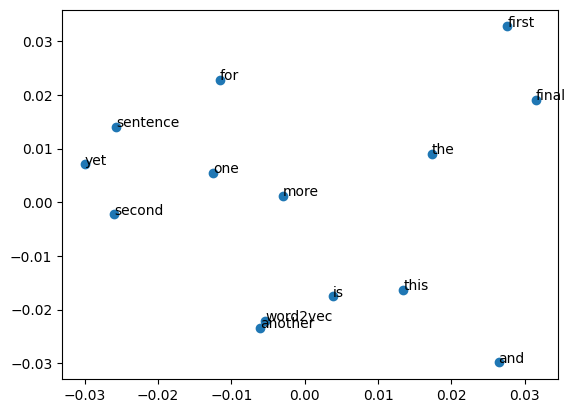

In [21]:
from sklearn.decomposition import PCA
from matplotlib import pyplot

# Versão 2d PCA dos vetores
X = new_model.wv[new_model.wv.index_to_key]
pca = PCA(n_components=2)
result = pca.fit_transform(X)

# Cria um gráfico em duas dimensões
pyplot.scatter(result[:, 0], result[:, 1])
palavras = list(new_model.wv.index_to_key)
for i, palavras in enumerate(palavras):
        pyplot.annotate(palavras, xy=(result[i, 0], result[i, 1]))
pyplot.show()